In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

# Cek lokasi file secara fleksibel (di direktori aktif atau folder data_raw)
file_name = "data_tembakau_bulanan_2017_2025.csv"
current_dir = Path.cwd()

if (current_dir / file_name).exists():
  csv_path = current_dir / file_name
elif (current_dir / "data_raw" / file_name).exists():
  csv_path = current_dir / "data_raw" / file_name
elif (current_dir.parent / file_name).exists():
  csv_path = current_dir.parent / file_name
elif (current_dir.parent / "data_raw" / file_name).exists():
  csv_path = current_dir.parent / "data_raw" / file_name
else:
  raise FileNotFoundError(
      f"File {file_name} tidak ditemukan di sekitar direktori kerja."
  )

df = pd.read_csv(csv_path)
print(f"Dataset berhasil dimuat dari: {csv_path}")
df.head()

Dataset berhasil dimuat dari: /home/khansa-mazaya-aad/Project/Integrasi Sistem Informasi Forecasting/Forecasting IPI Tembakau di Indonesia/data_raw/data_tembakau_bulanan_2017_2025.csv


,periode,tahun,bulan,ipi_tembakau,ipi_mom,ipi_yoy,netWgt,netwgt_rollsum12,netwgt_yoy,primaryValue,inflasi_tembakau,inflasi_tembakau_yoy,kursUSD,inflasi_umum,inflasi_umum_yoy
0,2017-01-01,2017,1,121.04,4.760256,8.917484,9115414.0,87829.732701,-13.500125,40795254.0,0.97,9.246507,13343.0,0.97,3.486338
1,2017-02-01,2017,2,107.61,-11.095506,-5.431057,6519569.0,86053.059899,-21.415393,31789301.0,0.63,8.588265,13347.0,0.23,3.817792
2,2017-03-01,2017,3,108.26,0.604033,-3.502986,7685036.0,86643.278018,8.319003,35482914.0,0.54,8.361928,13321.0,-0.02,3.600188
3,2017-04-01,2017,4,120.38,11.195271,6.549832,7133249.0,87116.851612,7.111061,33550212.0,0.43,8.200322,13327.0,0.09,4.162158
4,2017-05-01,2017,5,115.80,-3.804619,2.071397,12136569.0,92020.369322,67.793211,66359513.0,0.63,8.017841,13321.0,0.39,4.318028


In [2]:
import numpy as np
import pandas as pd

# Contoh pada DataFrame yang sudah Anda miliki (df):
# Pastikan kolom bulan bertipe integer (1 s.d. 12)
if "bulan" not in df.columns:
  df["bulan"] = pd.to_datetime(df["periode"]).dt.month

# Periode dalam 1 tahun = 12 bulan
T = 12.0

# 1. Transformasi Siklikal Musiman
df["sin_bulan"] = np.sin(2 * np.pi * df["bulan"] / T)
df["cos_bulan"] = np.cos(2 * np.pi * df["bulan"] / T)

# Cek hasil beberapa baris
print(
    df[["periode", "bulan", "sin_bulan", "cos_bulan"]].drop_duplicates("bulan")
)

       periode  bulan     sin_bulan     cos_bulan
0   2017-01-01      1  5.000000e-01  8.660254e-01
1   2017-02-01      2  8.660254e-01  5.000000e-01
2   2017-03-01      3  1.000000e+00  6.123234e-17
3   2017-04-01      4  8.660254e-01 -5.000000e-01
4   2017-05-01      5  5.000000e-01 -8.660254e-01
5   2017-06-01      6  1.224647e-16 -1.000000e+00
6   2017-07-01      7 -5.000000e-01 -8.660254e-01
7   2017-08-01      8 -8.660254e-01 -5.000000e-01
8   2017-09-01      9 -1.000000e+00 -1.836970e-16
9   2017-10-01     10 -8.660254e-01  5.000000e-01
10  2017-11-01     11 -5.000000e-01  8.660254e-01
11  2017-12-01     12 -2.449294e-16  1.000000e+00


In [3]:
import pandas as pd

# 1. Hitung harga satuan rata-rata tahun 2018 (hanya baris yang netWgt > 0)
mask_2018_valid = (df['tahun'] == 2018) & (df['netWgt'] > 0)
unit_price_2018 = (
    df.loc[mask_2018_valid, 'primaryValue'] / df.loc[mask_2018_valid, 'netWgt']
).mean()

# 2. Imputasi nilai netWgt pada Mei 2018
idx_target = df[(df['tahun'] == 2018) & (df['bulan'] == 5)].index[0]
df.loc[idx_target, 'netWgt'] = (
    df.loc[idx_target, 'primaryValue'] / unit_price_2018
)

print(
    f"Nilai netWgt Mei 2018 berhasil diperbarui menjadi: {df.loc[idx_target, 'netWgt']:,.0f} kg"
)

Nilai netWgt Mei 2018 berhasil diperbarui menjadi: 11,475,686 kg


In [4]:
df = df.drop(columns = ['tahun','bulan','primaryValue'])

In [5]:
df=df.set_index('periode')
df.head()

,ipi_tembakau,ipi_mom,ipi_yoy,netWgt,netwgt_rollsum12,netwgt_yoy,inflasi_tembakau,inflasi_tembakau_yoy,kursUSD,inflasi_umum,inflasi_umum_yoy,sin_bulan,cos_bulan
periode,,,,,,,,,,,,,
2017-01-01,121.04,4.760256,8.917484,9115414.0,87829.732701,-13.500125,0.97,9.246507,13343.0,0.97,3.486338,0.500000,8.660254e-01
2017-02-01,107.61,-11.095506,-5.431057,6519569.0,86053.059899,-21.415393,0.63,8.588265,13347.0,0.23,3.817792,0.866025,5.000000e-01
2017-03-01,108.26,0.604033,-3.502986,7685036.0,86643.278018,8.319003,0.54,8.361928,13321.0,-0.02,3.600188,1.000000,6.123234e-17
2017-04-01,120.38,11.195271,6.549832,7133249.0,87116.851612,7.111061,0.43,8.200322,13327.0,0.09,4.162158,0.866025,-5.000000e-01
2017-05-01,115.80,-3.804619,2.071397,12136569.0,92020.369322,67.793211,0.63,8.017841,13321.0,0.39,4.318028,0.500000,-8.660254e-01


In [6]:
df.info()

<class 'pandas.DataFrame'>
Index: 108 entries, 2017-01-01 to 2025-12-01
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ipi_tembakau          108 non-null    float64
 1   ipi_mom               108 non-null    float64
 2   ipi_yoy               108 non-null    float64
 3   netWgt                108 non-null    float64
 4   netwgt_rollsum12      108 non-null    float64
 5   netwgt_yoy            108 non-null    float64
 6   inflasi_tembakau      108 non-null    float64
 7   inflasi_tembakau_yoy  108 non-null    float64
 8   kursUSD               108 non-null    float64
 9   inflasi_umum          108 non-null    float64
 10  inflasi_umum_yoy      108 non-null    float64
 11  sin_bulan             108 non-null    float64
 12  cos_bulan             108 non-null    float64
dtypes: float64(13)
memory usage: 12.9 KB


In [7]:
# Statistik deskriptif keseluruhan untuk variabel numerik utama
cols_analisis = [
    'ipi_tembakau',
    'ipi_mom',
    'ipi_yoy',
    'netWgt',
    'inflasi_tembakau_yoy',
    'kursUSD',
]

desc_total = (
    df[cols_analisis]
    .describe()
    .T[['count', 'mean', 'std', 'min', '50%', 'max']]
)
desc_total.columns = [
    'Jumlah',
    'Rata-rata',
    'Std Deviasi',
    'Min',
    'Median',
    'Maks',
]
display(desc_total.round(2))

,Jumlah,Rata-rata,Std Deviasi,Min,Median,Maks
ipi_tembakau,108.0,135.24,16.25,93.47,133.70,167.10
ipi_mom,108.0,0.71,9.33,-22.80,0.88,33.95
ipi_yoy,108.0,3.51,11.08,-23.80,2.17,38.76
netWgt,108.0,11402087.72,3758387.58,4095784.00,11016896.50,22525507.24
inflasi_tembakau_yoy,108.0,6.65,2.01,3.40,6.70,11.30
kursUSD,108.0,14812.34,977.18,13319.00,14549.00,16787.00


In [8]:
# 1. Mengambil tahun langsung dari index
df['tahun'] = pd.to_datetime(df.index).year
# Atau jika index sudah DatetimeIndex: df['tahun'] = df.index.year

# 2. Ringkasan per tahun khusus target IPI
desc_tahunan_ipi = (
    df.groupby('tahun')['ipi_tembakau']
    .agg(
        Rata_rata='mean',
        Std_Deviasi='std',
        Min='min',
        Median='median',
        Maks='max',
    )
    .round(2)
)

display(desc_tahunan_ipi)

,Rata_rata,Std_Deviasi,Min,Median,Maks
tahun,,,,,
2017,115.54,6.48,105.98,117.86,122.58
2018,130.94,10.86,112.55,133.70,148.29
2019,125.34,14.70,93.47,124.36,150.34
2020,122.99,6.02,112.92,122.20,137.99
2021,126.96,8.24,111.96,126.14,138.18
2022,147.48,11.62,123.22,150.55,160.55
2023,147.59,12.85,127.57,147.51,167.10
2024,152.09,9.99,130.37,151.57,165.53
2025,148.28,8.65,132.82,149.26,163.33


/tmp/ipykernel_11297/795524643.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


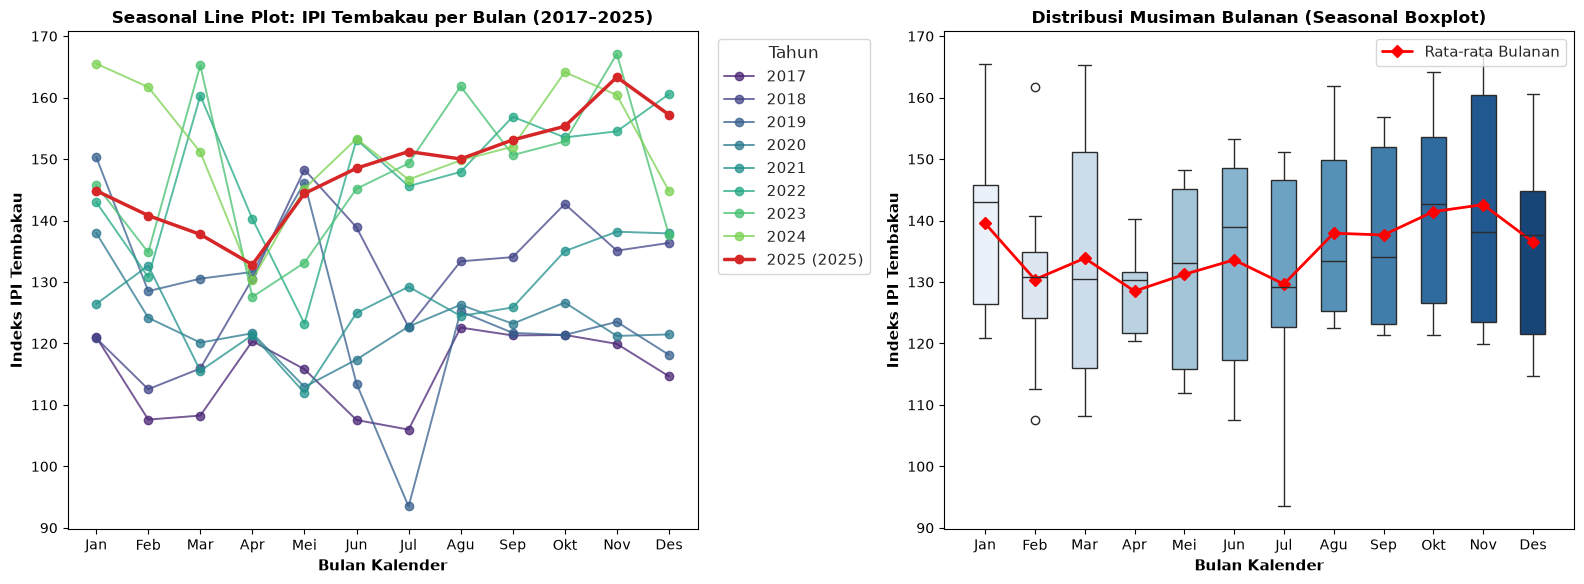

In [9]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Ekstraksi tahun dan bulan dari index
idx_dt = pd.to_datetime(df.index)
df['tahun'] = idx_dt.year
df['bulan'] = idx_dt.month

# 2. Siapkan kanvas 2 panel
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.set_theme(style='whitegrid')

nama_bulan = [
    'Jan',
    'Feb',
    'Mar',
    'Apr',
    'Mei',
    'Jun',
    'Jul',
    'Agu',
    'Sep',
    'Okt',
    'Nov',
    'Des',
]

# ==========================================================
# Panel 1: Seasonal Line Plot per Tahun (2017 - 2025)
# ==========================================================
pivot_ipi = df.pivot(index='bulan', columns='tahun', values='ipi_tembakau')
palette = sns.color_palette('viridis', len(pivot_ipi.columns))

for i, col in enumerate(pivot_ipi.columns):
  if col == 2025:
    axes[0].plot(
        pivot_ipi.index,
        pivot_ipi[col],
        marker='o',
        lw=2.5,
        color='#d62728',
        label=f'{col} (2025)',
    )
  else:
    axes[0].plot(
        pivot_ipi.index,
        pivot_ipi[col],
        marker='o',
        lw=1.4,
        color=palette[i],
        alpha=0.75,
        label=str(col),
    )

axes[0].set_xticks(range(1, 13))
axes[0].set_xticklabels(nama_bulan)
axes[0].set_title(
    'Seasonal Line Plot: IPI Tembakau per Bulan (2017–2025)',
    fontsize=12,
    fontweight='bold',
)
axes[0].set_xlabel('Bulan Kalender', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Indeks IPI Tembakau', fontsize=11, fontweight='bold')
axes[0].legend(
    title='Tahun', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True
)

# ==========================================================
# Panel 2: Seasonal Boxplot & Rata-rata Bulanan Lintas Tahun
# ==========================================================
sns.boxplot(
    data=df, x='bulan', y='ipi_tembakau', palette='Blues', ax=axes[1], width=0.5
)

# Tambahkan garis titik rata-rata bulanan
mean_monthly = df.groupby('bulan')['ipi_tembakau'].mean()
axes[1].plot(
    range(0, 12),
    mean_monthly.values,
    color='red',
    marker='D',
    lw=2,
    label='Rata-rata Bulanan',
)

axes[1].set_xticks(range(0, 12))
axes[1].set_xticklabels(nama_bulan)
axes[1].set_title(
    'Distribusi Musiman Bulanan (Seasonal Boxplot)',
    fontsize=12,
    fontweight='bold',
)
axes[1].set_xlabel('Bulan Kalender', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Indeks IPI Tembakau', fontsize=11, fontweight='bold')
axes[1].legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.show()

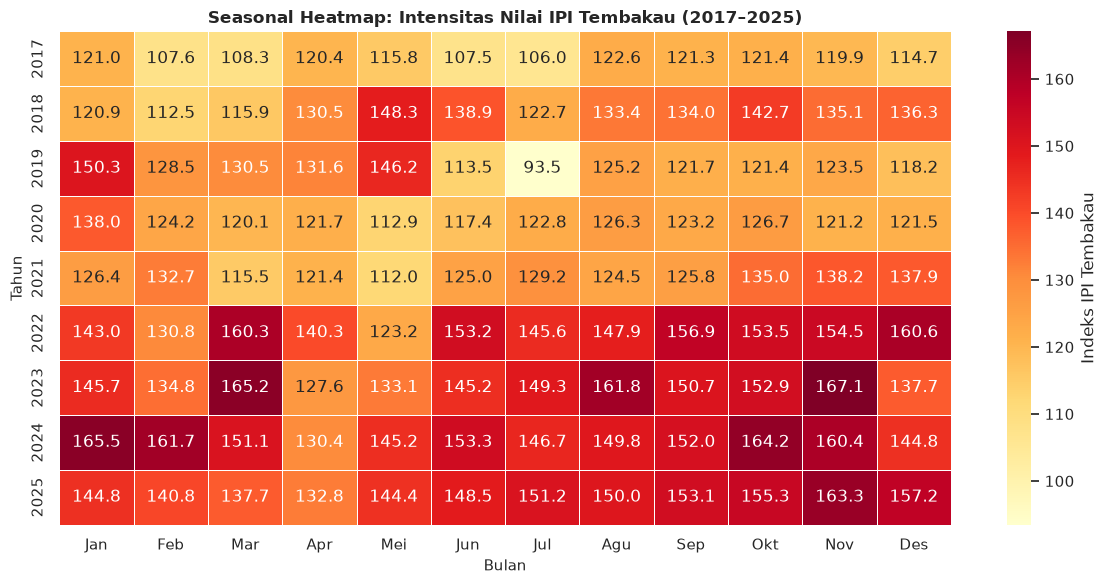

In [10]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Pastikan tahun dan bulan tersedia
idx_dt = pd.to_datetime(df.index)
df['tahun'] = idx_dt.year
df['bulan_num'] = idx_dt.month

nama_bulan = [
    'Jan',
    'Feb',
    'Mar',
    'Apr',
    'Mei',
    'Jun',
    'Jul',
    'Agu',
    'Sep',
    'Okt',
    'Nov',
    'Des',
]

# Bentuk matriks Tahun x Bulan
pivot_ipi = df.pivot(index='tahun', columns='bulan_num', values='ipi_tembakau')
pivot_ipi.columns = nama_bulan

plt.figure(figsize=(12, 6))
sns.heatmap(
    pivot_ipi,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd',
    cbar_kws={'label': 'Indeks IPI Tembakau'},
    linewidths=0.5,
)
plt.title(
    'Seasonal Heatmap: Intensitas Nilai IPI Tembakau (2017–2025)',
    fontsize=12,
    fontweight='bold',
)
plt.ylabel('Tahun', fontsize=11)
plt.xlabel('Bulan', fontsize=11)
plt.tight_layout()
plt.show()

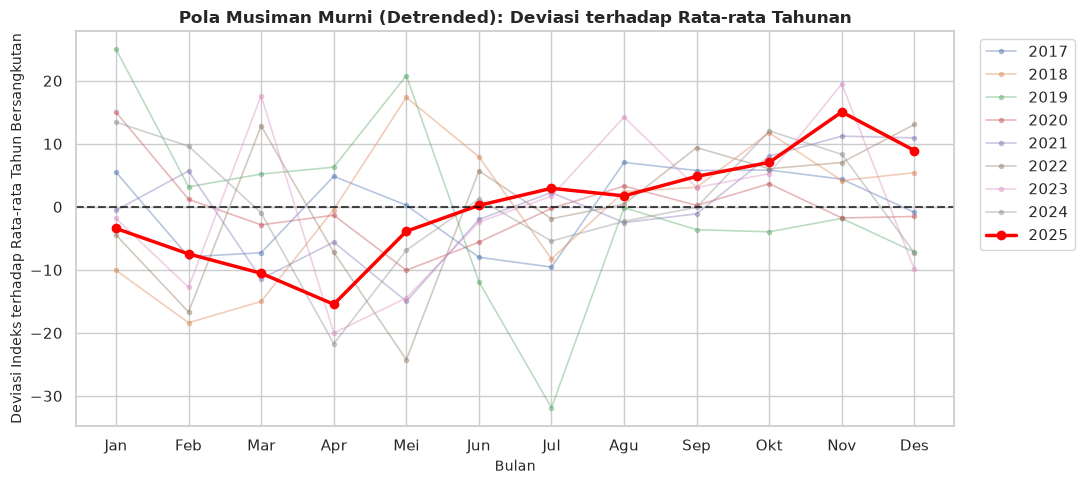

In [11]:
# Hitung selisih terhadap rata-rata tahunan masing-masing
df['ipi_detrended'] = df.groupby('tahun')['ipi_tembakau'].transform(
    lambda x: x - x.mean()
)

pivot_detrend = df.pivot(
    index='bulan_num', columns='tahun', values='ipi_detrended'
)

plt.figure(figsize=(11, 5))
for thn in pivot_detrend.columns:
  if thn == 2025:
    plt.plot(
        pivot_detrend.index,
        pivot_detrend[thn],
        marker='o',
        lw=2.5,
        color='red',
        label='2025',
    )
  else:
    plt.plot(
        pivot_detrend.index,
        pivot_detrend[thn],
        marker='.',
        lw=1.2,
        alpha=0.4,
        label=str(thn),
    )

plt.axhline(0, color='black', linestyle='--', alpha=0.7)
plt.xticks(range(1, 13), nama_bulan)
plt.title(
    'Pola Musiman Murni (Detrended): Deviasi terhadap Rata-rata Tahunan',
    fontsize=12,
    fontweight='bold',
)
plt.ylabel('Deviasi Indeks terhadap Rata-rata Tahun Bersangkutan', fontsize=10)
plt.xlabel('Bulan', fontsize=10)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [12]:
import warnings
import pandas as pd
from statsmodels.tsa.stattools import adfuller, kpss

# Mengabaikan peringatan batas interpolasi p-value pada KPSS
warnings.filterwarnings('ignore')


def uji_adf_kpss(df, kolom_list, alpha=0.05):
  hasil = []

  for col in kolom_list:
    series = df[col].dropna()

    # 1. Uji ADF (H0: Memiliki unit root / Tidak Stasioner)
    adf_res = adfuller(series, autolag='AIC')
    adf_stat, adf_p = adf_res[0], adf_res[1]
    adf_stasioner = adf_p < alpha

    # 2. Uji KPSS (H0: Data Stasioner di sekitar konstan/mean)
    kpss_res = kpss(series, regression='c', nlags='auto')
    kpss_stat, kpss_p = kpss_res[0], kpss_res[1]
    kpss_stasioner = kpss_p >= alpha

    # 3. Pengambilan Keputusan Gabungan
    if adf_stasioner and kpss_stasioner:
      kesimpulan = 'Stasioner Murni'
    elif not adf_stasioner and not kpss_stasioner:
      kesimpulan = 'Tidak Stasioner (Unit Root)'
    elif adf_stasioner and not kpss_stasioner:
      kesimpulan = 'Trend/Seasonal Stationary'
    else:
      kesimpulan = 'Inconclusive'

    hasil.append({
        'Variabel': col,
        'ADF Stat': round(adf_stat, 4),
        'ADF p-val': round(adf_p, 4),
        'Status ADF': 'Stasioner' if adf_stasioner else 'Tidak Stasioner',
        'KPSS Stat': round(kpss_stat, 4),
        'KPSS p-val': round(kpss_p, 4),
        'Status KPSS': 'Stasioner' if kpss_stasioner else 'Tidak Stasioner',
        'Kesimpulan Akhir': kesimpulan,
    })

  return pd.DataFrame(hasil)


# Daftar kolom yang ingin diuji
kolom_uji = [
    'ipi_tembakau',
    'ipi_mom',
    'ipi_yoy',
    'netWgt',
    'netwgt_rollsum12',
    'netwgt_yoy',
    'inflasi_tembakau',
    'inflasi_tembakau_yoy',
    'kursUSD',
    'inflasi_umum',
    'inflasi_umum_yoy',
]

# Eksekusi pengujian
df_hasil_stasioneritas = uji_adf_kpss(df, kolom_uji)
display(df_hasil_stasioneritas)

,Variabel,ADF Stat,ADF p-val,Status ADF,KPSS Stat,KPSS p-val,Status KPSS,Kesimpulan Akhir
0,ipi_tembakau,-2.0559,0.2626,Tidak Stasioner,1.3981,0.01,Tidak Stasioner,Tidak Stasioner (Unit Root)
1,ipi_mom,-3.2553,0.0170,Stasioner,0.1071,0.10,Stasioner,Stasioner Murni
2,ipi_yoy,-2.8909,0.0464,Stasioner,0.1002,0.10,Stasioner,Stasioner Murni
3,netWgt,1.7422,0.9982,Tidak Stasioner,1.2196,0.01,Tidak Stasioner,Tidak Stasioner (Unit Root)
4,netwgt_rollsum12,2.3807,0.9990,Tidak Stasioner,1.1953,0.01,Tidak Stasioner,Tidak Stasioner (Unit Root)
5,netwgt_yoy,-8.1545,0.0000,Stasioner,0.1673,0.10,Stasioner,Stasioner Murni
6,inflasi_tembakau,-4.8455,0.0000,Stasioner,0.1387,0.10,Stasioner,Stasioner Murni
7,inflasi_tembakau_yoy,-1.6469,0.4587,Tidak Stasioner,0.1343,0.10,Stasioner,Inconclusive
8,kursUSD,-1.6739,0.4446,Tidak Stasioner,1.6302,0.01,Tidak Stasioner,Tidak Stasioner (Unit Root)
9,inflasi_umum,-5.8192,0.0000,Stasioner,0.0751,0.10,Stasioner,Stasioner Murni


In [13]:
import warnings
import pandas as pd
from statsmodels.tsa.stattools import adfuller, kpss

# Mengabaikan peringatan batas interpolasi p-value pada KPSS
warnings.filterwarnings('ignore')


def uji_adf_kpss(df, kolom_list, alpha=0.05):
  hasil = []

  for col in kolom_list:
    series = df[col].dropna()

    # 1. Uji ADF (H0: Memiliki unit root / Tidak Stasioner)
    adf_res = adfuller(series, autolag='AIC')
    adf_stat, adf_p = adf_res[0], adf_res[1]
    adf_stasioner = adf_p < alpha

    # 2. Uji KPSS (H0: Data Stasioner di sekitar konstan/mean)
    kpss_res = kpss(series, regression='c', nlags='auto')
    kpss_stat, kpss_p = kpss_res[0], kpss_res[1]
    kpss_stasioner = kpss_p >= alpha

    # 3. Pengambilan Keputusan Gabungan
    if adf_stasioner and kpss_stasioner:
      kesimpulan = 'Stasioner Murni'
    elif not adf_stasioner and not kpss_stasioner:
      kesimpulan = 'Tidak Stasioner (Unit Root)'
    elif adf_stasioner and not kpss_stasioner:
      kesimpulan = 'Trend/Seasonal Stationary'
    else:
      kesimpulan = 'Inconclusive'

    hasil.append({
        'Variabel': col,
        'ADF Stat': round(adf_stat, 4),
        'ADF p-val': round(adf_p, 4),
        'Status ADF': 'Stasioner' if adf_stasioner else 'Tidak Stasioner',
        'KPSS Stat': round(kpss_stat, 4),
        'KPSS p-val': round(kpss_p, 4),
        'Status KPSS': 'Stasioner' if kpss_stasioner else 'Tidak Stasioner',
        'Kesimpulan Akhir': kesimpulan,
    })

  return pd.DataFrame(hasil)


# Daftar kolom yang ingin diuji
kolom_uji = [
    'ipi_tembakau',
    'ipi_mom',
    'ipi_yoy',
    'netWgt',
    'netwgt_rollsum12',
    'netwgt_yoy',
    'inflasi_tembakau',
    'inflasi_tembakau_yoy',
    'kursUSD',
    'inflasi_umum',
    'inflasi_umum_yoy',
]

# Eksekusi pengujian
df_hasil_stasioneritas = uji_adf_kpss(df, kolom_uji)
display(df_hasil_stasioneritas)


,Variabel,ADF Stat,ADF p-val,Status ADF,KPSS Stat,KPSS p-val,Status KPSS,Kesimpulan Akhir
0,ipi_tembakau,-2.0559,0.2626,Tidak Stasioner,1.3981,0.01,Tidak Stasioner,Tidak Stasioner (Unit Root)
1,ipi_mom,-3.2553,0.0170,Stasioner,0.1071,0.10,Stasioner,Stasioner Murni
2,ipi_yoy,-2.8909,0.0464,Stasioner,0.1002,0.10,Stasioner,Stasioner Murni
3,netWgt,1.7422,0.9982,Tidak Stasioner,1.2196,0.01,Tidak Stasioner,Tidak Stasioner (Unit Root)
4,netwgt_rollsum12,2.3807,0.9990,Tidak Stasioner,1.1953,0.01,Tidak Stasioner,Tidak Stasioner (Unit Root)
5,netwgt_yoy,-8.1545,0.0000,Stasioner,0.1673,0.10,Stasioner,Stasioner Murni
6,inflasi_tembakau,-4.8455,0.0000,Stasioner,0.1387,0.10,Stasioner,Stasioner Murni
7,inflasi_tembakau_yoy,-1.6469,0.4587,Tidak Stasioner,0.1343,0.10,Stasioner,Inconclusive
8,kursUSD,-1.6739,0.4446,Tidak Stasioner,1.6302,0.01,Tidak Stasioner,Tidak Stasioner (Unit Root)
9,inflasi_umum,-5.8192,0.0000,Stasioner,0.0751,0.10,Stasioner,Stasioner Murni


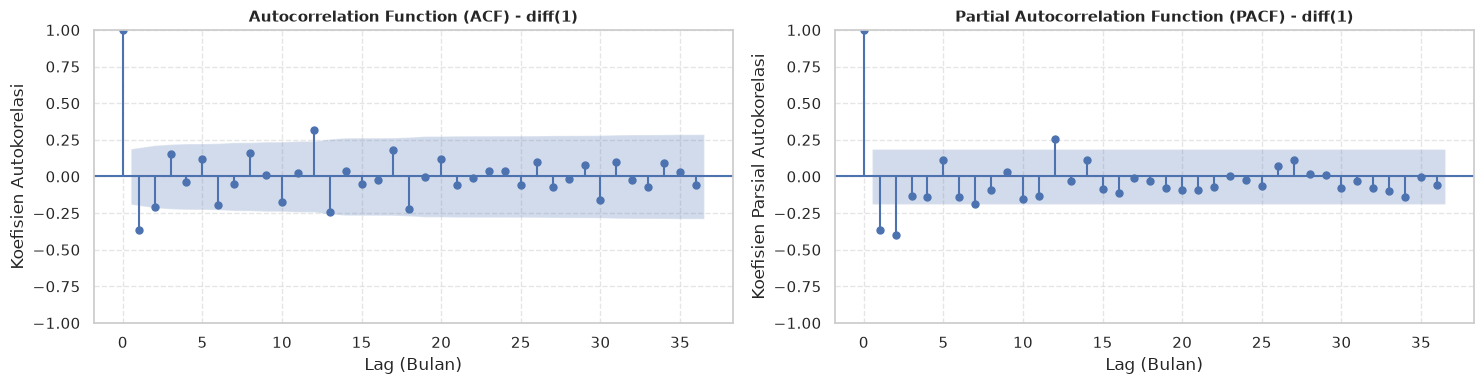

In [14]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# 1. Menyiapkan data diferensiasi pertama
diff_ipi = df['ipi_tembakau'].diff(1).dropna()

# 2. Membuat kanvas plot ACF dan PACF berdampingan
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

# Plot ACF
plot_acf(diff_ipi, lags=36, ax=axes[0])
axes[0].set_title(
    'Autocorrelation Function (ACF) - diff(1)', fontsize=11, fontweight='bold'
)
axes[0].set_xlabel('Lag (Bulan)')
axes[0].set_ylabel('Koefisien Autokorelasi')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Plot PACF (gunakan method='ywm' atau method='ols')
plot_pacf(diff_ipi, lags=36, ax=axes[1], method='ywm')
axes[1].set_title(
    'Partial Autocorrelation Function (PACF) - diff(1)',
    fontsize=11,
    fontweight='bold',
)
axes[1].set_xlabel('Lag (Bulan)')
axes[1].set_ylabel('Koefisien Parsial Autokorelasi')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [15]:
import numpy as np
import pandas as pd

# 1. Konversi indeks ke format DatetimeIndex
df.index = pd.to_datetime(df.index)

# 2. Urutkan berdasarkan waktu
df = df.sort_index()

# -------------------------------------------------------------
# Pembagian Data: Train (2017 - 2023), Test (2024 - 2025)
# -------------------------------------------------------------
split_date = "2024-01-01"

train = df.loc[df.index < split_date].copy()
test = df.loc[df.index >= split_date].copy()

print(f"Total baris data: {len(df)}")
print(
    f"Data Train: {len(train)} baris ({train.index.min().strftime('%Y-%m')} s.d. {train.index.max().strftime('%Y-%m')})"
)
print(
    f"Data Test : {len(test)} baris ({test.index.min().strftime('%Y-%m')} s.d. {test.index.max().strftime('%Y-%m')})"
)

Total baris data: 108
Data Train: 84 baris (2017-01 s.d. 2023-12)
Data Test : 24 baris (2024-01 s.d. 2025-12)


In [16]:
y_train = train['ipi_tembakau']
y_test = test['ipi_tembakau']

x_train = train.drop(columns = 'ipi_tembakau')
x_test = test.drop(columns='ipi_tembakau')

In [17]:
x_train.columns

Index(['ipi_mom', 'ipi_yoy', 'netWgt', 'netwgt_rollsum12', 'netwgt_yoy',
       'inflasi_tembakau', 'inflasi_tembakau_yoy', 'kursUSD', 'inflasi_umum',
       'inflasi_umum_yoy', 'sin_bulan', 'cos_bulan', 'tahun', 'bulan',
       'bulan_num', 'ipi_detrended'],
      dtype='str')

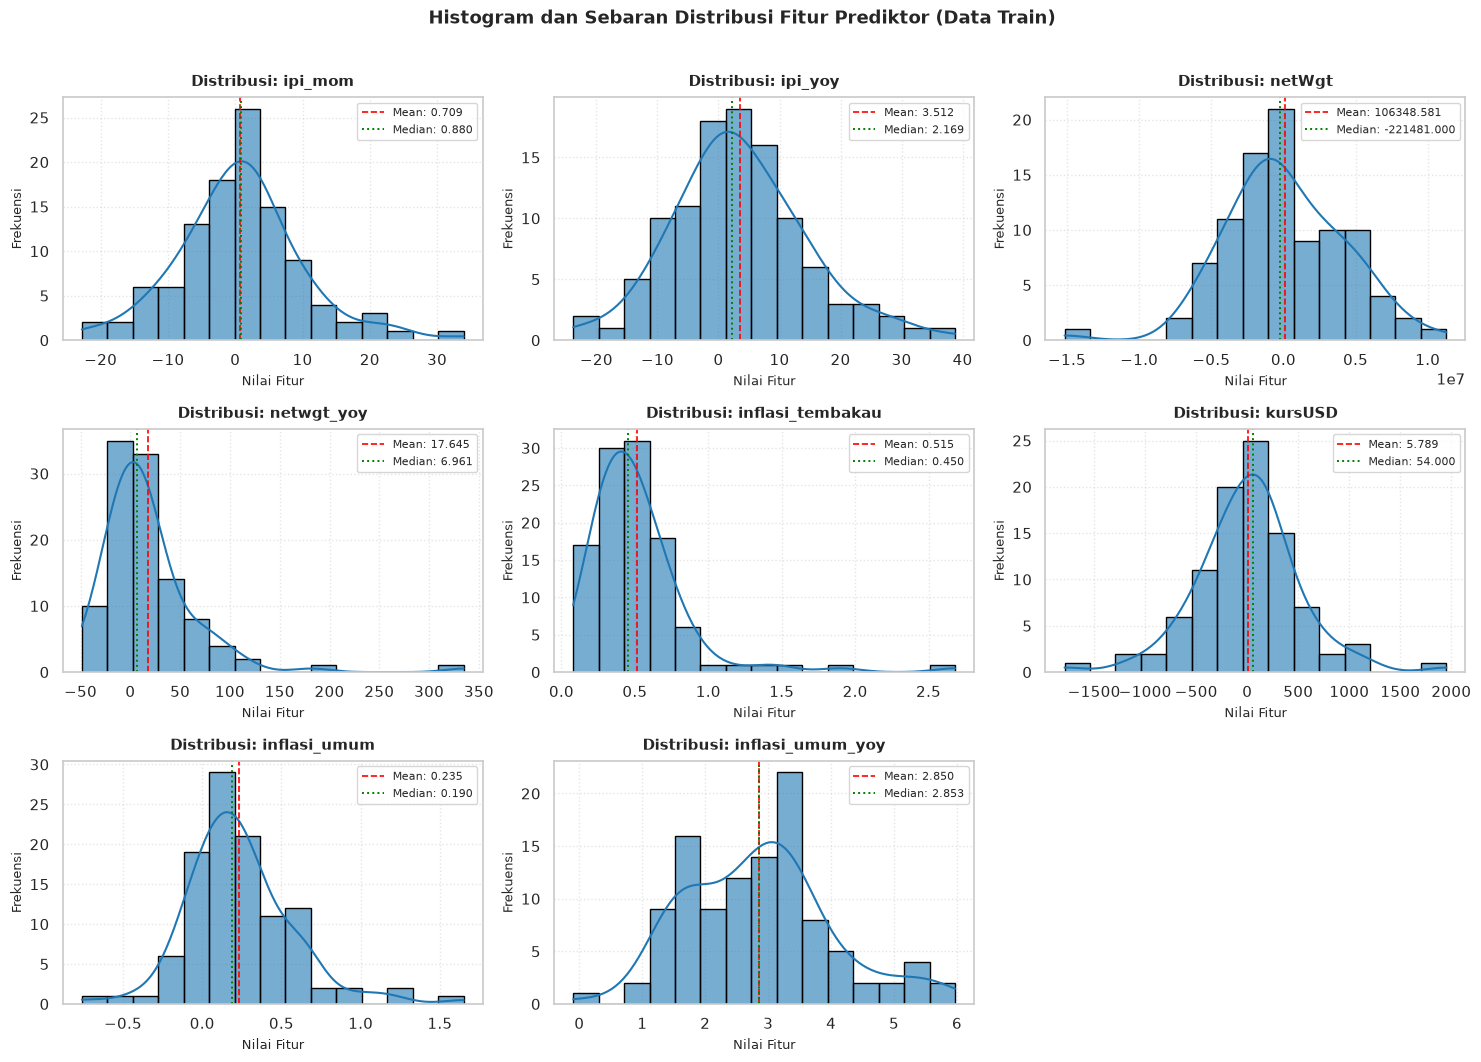

=== Ringkasan Karakteristik Distribusi Prediktor ===


,Skewness,Kurtosis,Mean,Std Dev
ipi_mom,0.419,1.510,0.709,9.325
ipi_yoy,0.388,0.725,3.512,11.079
netWgt,-0.127,1.216,106348.581,4133571.250
netwgt_yoy,3.167,16.695,17.645,48.747
inflasi_tembakau,3.229,15.605,0.515,0.348
kursUSD,0.118,2.824,5.789,513.926
inflasi_umum,0.913,3.102,0.235,0.338
inflasi_umum_yoy,0.449,0.243,2.850,1.159


In [18]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns


train_corr = df.copy()
train_corr['ipi_tembakau'] = train_corr['ipi_tembakau'].diff(1).diff(12).dropna()
train_corr['netWgt'] = train_corr['netWgt'].diff(1).diff(12).dropna()
train_corr['kursUSD'] = train_corr['kursUSD'].diff(1).diff(12).dropna()

# ==============================================================================
# 1. DAFTAR FITUR PREDIKTOR YANG DIANALISIS
# ==============================================================================
# Menggunakan data latih terisolasi (train_corr)
fitur_prediktor = [
    'ipi_mom', 'ipi_yoy', 'netWgt', 'netwgt_yoy',
       'inflasi_tembakau', 'kursUSD', 'inflasi_umum',
       'inflasi_umum_yoy'
]

# Pastikan hanya memilih kolom yang ada di dalam DataFrame
fitur_plot = [col for col in fitur_prediktor if col in train_corr.columns]

# ==============================================================================
# 2. SETUP GRID SUBPLOT HISTOGRAM
# ==============================================================================
n_cols = 3
n_rows = int(np.ceil(len(fitur_plot) / n_cols))

plt.figure(figsize=(15, 3.5 * n_rows))

for i, col in enumerate(fitur_plot):
  ax = plt.subplot(n_rows, n_cols, i + 1)

  # Histogram dengan kurva KDE (Kernel Density Estimation)
  sns.histplot(
      train_corr[col],
      kde=True,
      bins=15,
      color='#1f77b4',
      edgecolor='black',
      alpha=0.6,
      ax=ax,
  )

  # Garis penanda rata-rata (mean) dan median
  mean_val = train_corr[col].mean()
  median_val = train_corr[col].median()

  ax.axvline(
      mean_val,
      color='red',
      linestyle='--',
      linewidth=1.2,
      label=f'Mean: {mean_val:.3f}',
  )
  ax.axvline(
      median_val,
      color='green',
      linestyle=':',
      linewidth=1.4,
      label=f'Median: {median_val:.3f}',
  )

  ax.set_title(f'Distribusi: {col}', fontsize=11, fontweight='bold', pad=8)
  ax.set_xlabel('Nilai Fitur', fontsize=9)
  ax.set_ylabel('Frekuensi', fontsize=9)
  ax.grid(True, linestyle=':', alpha=0.5)
  ax.legend(fontsize=8, loc='upper right')

# Hapus subplot kosong jika jumlah fitur tidak pas kelipatan n_cols
for j in range(len(fitur_plot) + 1, n_rows * n_cols + 1):
  plt.subplot(n_rows, n_cols, j).set_visible(False)

plt.suptitle(
    'Histogram dan Sebaran Distribusi Fitur Prediktor (Data Train)',
    fontsize=13,
    fontweight='bold',
    y=1.01,
)
plt.tight_layout()
plt.show()

# ==============================================================================
# 3. RINGKASAN DESKRIPTIF BENTUK DISTRIBUSI (SKEWNESS & KURTOSIS)
# ==============================================================================
df_dist_summary = pd.DataFrame({
    'Skewness': train_corr[fitur_plot].skew(),
    'Kurtosis': train_corr[fitur_plot].kurtosis(),
    'Mean': train_corr[fitur_plot].mean(),
    'Std Dev': train_corr[fitur_plot].std(),
})

print('=== Ringkasan Karakteristik Distribusi Prediktor ===')
display(df_dist_summary.round(3))

In [19]:
import numpy as np

train_corr['log_inflasi_tembakau'] = np.log(train_corr['inflasi_tembakau'])


In [20]:
train_corr['log_inflasi_tembakau'].isnull().sum()

np.int64(0)

In [21]:
from scipy.stats import pearsonr, yeojohnson

# Transformasi Yeo-Johnson mencari lambda optimal secara otomatis
train_corr['yj_netwgt_yoy'], lmbda = yeojohnson(train_corr['netwgt_yoy'])


In [22]:
train_corr['yj_netwgt_yoy']

periode
2017-01-01   -18.837922
2017-02-01   -31.990525
2017-03-01     6.435113
2017-04-01     5.607212
2017-05-01    38.607518
                ...    
2025-08-01    13.972220
2025-09-01    19.978172
2025-10-01    -2.520248
2025-11-01     8.167265
2025-12-01    48.846494
Name: yj_netwgt_yoy, Length: 108, dtype: float64

In [23]:
train_corr = train_corr.dropna()

In [24]:
train_corr.columns

Index(['ipi_tembakau', 'ipi_mom', 'ipi_yoy', 'netWgt', 'netwgt_rollsum12',
       'netwgt_yoy', 'inflasi_tembakau', 'inflasi_tembakau_yoy', 'kursUSD',
       'inflasi_umum', 'inflasi_umum_yoy', 'sin_bulan', 'cos_bulan', 'tahun',
       'bulan', 'bulan_num', 'ipi_detrended', 'log_inflasi_tembakau',
       'yj_netwgt_yoy'],
      dtype='str')

In [25]:
train_corr.isnull().sum()

ipi_tembakau            0
ipi_mom                 0
ipi_yoy                 0
netWgt                  0
netwgt_rollsum12        0
netwgt_yoy              0
inflasi_tembakau        0
inflasi_tembakau_yoy    0
kursUSD                 0
inflasi_umum            0
inflasi_umum_yoy        0
sin_bulan               0
cos_bulan               0
tahun                   0
bulan                   0
bulan_num               0
ipi_detrended           0
log_inflasi_tembakau    0
yj_netwgt_yoy           0
dtype: int64

In [26]:
import pandas as pd
from scipy.stats import pearsonr, spearmanr

# 1. Tentukan target stasioner
target_col = 'ipi_tembakau'  # Pastikan kolom ini sudah stasioner di train_corr

kandidat_fitur = [
    'netWgt',
    'yj_netwgt_yoy',
    'kursUSD',
    'log_inflasi_tembakau',
    'inflasi_umum',
    'inflasi_umum_yoy',
]

hasil = []

for col in kandidat_fitur:
  if col in train_corr.columns:
    # Lakukan dropna secara berpasangan agar tidak error jika ada baris kosong
    valid_data = train_corr[[col, target_col]].dropna()

    x = valid_data[col]
    y = valid_data[target_col]

    # Pastikan data memiliki varians (tidak konstan)
    if x.nunique() > 1 and y.nunique() > 1:
      r_p, p_p = pearsonr(x, y)
      r_s, p_s = spearmanr(x, y)

      hasil.append({
          'Fitur': col,
          'Pearson (r)': round(r_p, 4),
          'p-val Pearson': round(p_p, 4),
          'Spearman (rho)': round(r_s, 4),
          'p-val Spearman': round(p_s, 4),
          'Linear Valid (p < 0.05)': 'Ya' if p_p < 0.05 else 'Tidak',
      })

df_hasil_korelasi = pd.DataFrame(hasil).sort_values(
    by='Pearson (r)', key=abs, ascending=False
)

display(df_hasil_korelasi.reset_index(drop=True))

,Fitur,Pearson (r),p-val Pearson,Spearman (rho),p-val Spearman,Linear Valid (p < 0.05)
0,netWgt,0.2929,0.0040,0.2214,0.0310,Ya
1,yj_netwgt_yoy,0.2579,0.0116,0.3263,0.0013,Ya
2,kursUSD,0.2014,0.0504,0.2249,0.0284,Tidak
3,log_inflasi_tembakau,-0.1054,0.3095,-0.1302,0.2084,Tidak
4,inflasi_umum,0.0870,0.4016,0.0719,0.4888,Tidak
5,inflasi_umum_yoy,-0.0330,0.7512,-0.0258,0.8038,Tidak


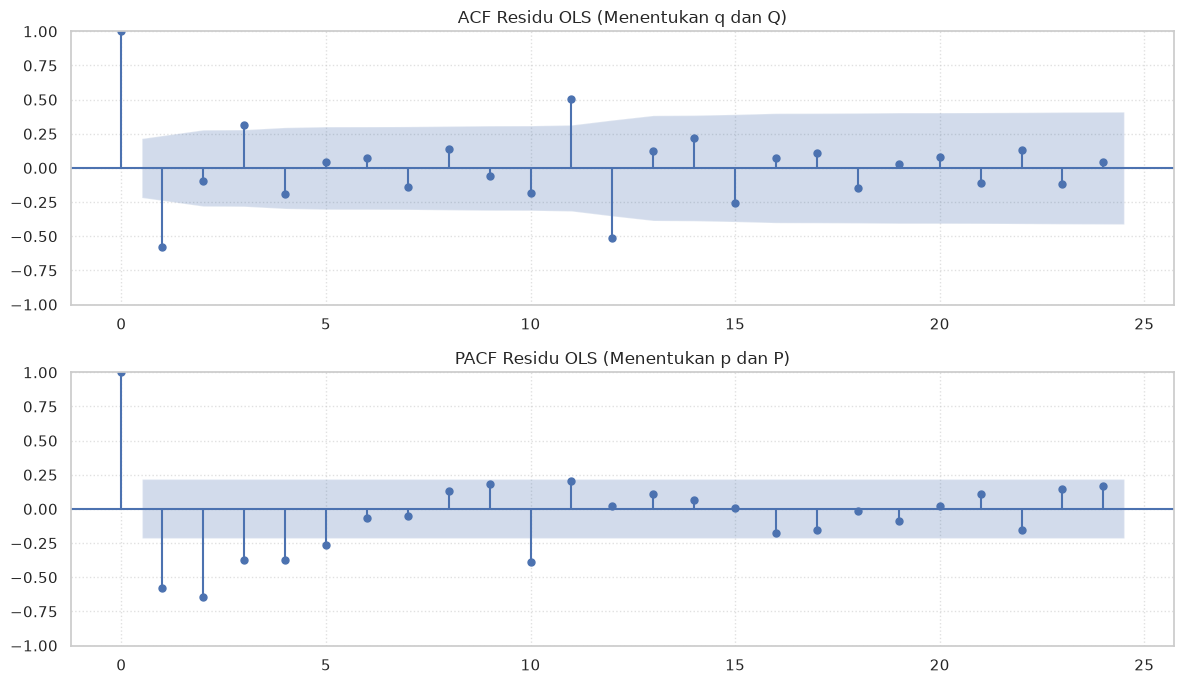

In [28]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# 1. Regresi OLS untuk mengisolasi galat regresi
df_ols = train_corr[['ipi_tembakau', 'netWgt', 'yj_netwgt_yoy']].dropna()
X_const = sm.add_constant(df_ols[['netWgt', 'yj_netwgt_yoy']])
ols_res = sm.OLS(df_ols['ipi_tembakau'], X_const).fit()

# 2. Diferensiasi residu (d=1, D=1, s=12)
resid_diff = ols_res.resid.diff(1).diff(12).dropna()

# Tentukan batas lag aman
safe_lags = min(24, len(resid_diff) // 2 - 1)

# 3. Plot ACF dan PACF
fig, axes = plt.subplots(2, 1, figsize=(12, 7))

plot_acf(
    resid_diff,
    lags=safe_lags,
    ax=axes[0],
    alpha=0.05,
    title='ACF Residu OLS (Menentukan q dan Q)',
)
axes[0].grid(True, linestyle=':', alpha=0.6)

plot_pacf(
    resid_diff,
    lags=safe_lags,
    ax=axes[1],
    alpha=0.05,
    title='PACF Residu OLS (Menentukan p dan P)',
    method='ywm',
)
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

In [ ]:
test.columns

Index(['ipi_tembakau', 'ipi_mom', 'ipi_yoy', 'netWgt', 'netwgt_rollsum12',
       'netwgt_yoy', 'inflasi_tembakau', 'inflasi_tembakau_yoy', 'kursUSD',
       'inflasi_umum', 'inflasi_umum_yoy', 'sin_bulan', 'cos_bulan', 'tahun',
       'bulan', 'bulan_num', 'ipi_detrended'],
      dtype='str')

In [ ]:
train_final = train.copy()
test_final = test.copy()

import numpy as np

train_final['log_inflasi_tembakau'] = np.log(train_final['inflasi_tembakau'])
train_final['yj_netwgt_yoy'], lmbda = yeojohnson(train_final['netwgt_yoy'])

train_final = train_final[['log_inflasi_tembakau','yj_netwgt_yoy','netWgt','ipi_tembakau']]


test_final['log_inflasi_tembakau'] = np.log(test_final['inflasi_tembakau'])
test_final['yj_netwgt_yoy'], lmbda = yeojohnson(test_final['netwgt_yoy'])

test_final = test_final[['log_inflasi_tembakau','yj_netwgt_yoy','netWgt','ipi_tembakau']]




In [ ]:
import itertools
import warnings
import numpy as np
import pandas as pd
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    root_mean_squared_error,
)
from sklearn.model_selection import TimeSeriesSplit
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings('ignore')

# ==============================================================================
# 1. PERSIAPAN DATA TARGET & VARIABEL EKSOGEN TERPILIH
# ==============================================================================
exog_cols = ['netWgt', 'yj_netwgt_yoy']

# Pastikan data pada train_corr sejajar dan bersih dari NaN
df_model = train_final[['ipi_tembakau'] + exog_cols].dropna()

y_train_full = df_model['ipi_tembakau']
X_train_full = df_model[exog_cols]

# ==============================================================================
# 2. RUANG PENCARIAN PARAMETER (GRID)
# ==============================================================================
p = [0, 1, 2]
d = [1]
q = [0, 1]
P = [0, 1]
D = [1]
Q = [0, 1]
s = 12

kandidat_order = list(itertools.product(p, d, q))
kandidat_seasonal = [
    (p_s, d_s, q_s, s) for p_s, d_s, q_s in itertools.product(P, D, Q)
]

total_kombinasi = len(kandidat_order) * len(kandidat_seasonal)
print(f"Memulai Grid Search SARIMAX dengan CV: {total_kombinasi} kombinasi ordo...")
print(f"Fitur eksogen yang disertakan: {exog_cols}")

# ==============================================================================
# 3. SETUP TIME-SERIES CROSS VALIDATION
# ==============================================================================
n_splits = 4
tscv = TimeSeriesSplit(n_splits=n_splits)

hasil_grid = []

# ==============================================================================
# 4. ITERASI EVALUASI GRID SEARCH
# ==============================================================================
for order in kandidat_order:
    for s_order in kandidat_seasonal:
        fold_rmse = []
        fold_mae = []
        fold_mape = []
        berhasil = True

        for train_idx, val_idx in tscv.split(df_model):
            # Split Target
            cv_train_y = y_train_full.iloc[train_idx]
            cv_val_y = y_train_full.iloc[val_idx]

            # Split Eksogen
            cv_train_X = X_train_full.iloc[train_idx]
            cv_val_X = X_train_full.iloc[val_idx]

            try:
                # Fit SARIMAX dengan eksogen
                model = SARIMAX(
                    endog=cv_train_y,
                    exog=cv_train_X,
                    order=order,
                    seasonal_order=s_order,
                    enforce_stationarity=False,
                    enforce_invertibility=False
                )
                res = model.fit(disp=False, maxiter=50)

                # Forecast sepanjang ukuran fold validasi dengan eksogen validasi
                pred = res.forecast(steps=len(cv_val_y), exog=cv_val_X)

                # Hitung metrik evaluasi per fold
                rmse = root_mean_squared_error(cv_val_y, pred)
                mae = mean_absolute_error(cv_val_y, pred)
                mape = mean_absolute_percentage_error(cv_val_y, pred) * 100

                fold_rmse.append(rmse)
                fold_mae.append(mae)
                fold_mape.append(mape)
            except Exception:
                berhasil = False
                break

        if berhasil and len(fold_rmse) == n_splits:
            hasil_grid.append({
                'order': order,
                'seasonal_order': s_order,
                'mean_cv_rmse': round(np.mean(fold_rmse), 3),
                'mean_cv_mae': round(np.mean(fold_mae), 3),
                'mean_cv_mape': round(np.mean(fold_mape), 3),
                'std_cv_rmse': round(np.std(fold_rmse), 3),
                'std_cv_mape': round(np.std(fold_mape), 3),
            })

# ==============================================================================
# 5. RINGKAS DAN TAMPILKAN HASIL TERBAIK
# ==============================================================================
df_hasil = (
    pd.DataFrame(hasil_grid)
    .sort_values(by='mean_cv_rmse')
    .reset_index(drop=True)
)

print('\n=== Top 5 Model SARIMAX Terbaik (Berdasarkan CV RMSE) ===')
display(df_hasil.head(5))

Memulai Grid Search SARIMAX dengan CV: 24 kombinasi ordo...
Fitur eksogen yang disertakan: ['netWgt', 'yj_netwgt_yoy']

=== Top 5 Model SARIMAX Terbaik (Berdasarkan CV RMSE) ===


,order,seasonal_order,mean_cv_rmse,mean_cv_mae,mean_cv_mape,std_cv_rmse,std_cv_mape
0,"(0, 1, 0)","(0, 1, 0, 12)",20.548,17.146,12.903,1.572,2.264
1,"(0, 1, 1)","(1, 1, 0, 12)",20.602,17.503,13.175,5.161,3.504
2,"(1, 1, 0)","(0, 1, 0, 12)",20.616,17.226,12.954,1.431,2.142
3,"(1, 1, 1)","(1, 1, 0, 12)",20.622,17.579,13.252,5.047,3.496
4,"(1, 1, 1)","(0, 1, 0, 12)",20.628,17.199,12.968,2.182,2.725


In [ ]:
import pandas as pd
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    root_mean_squared_error,
)
from statsmodels.tsa.statespace.sarimax import SARIMAX

# 1. Siapkan data eksogen data test (harus sama urutan kolomnya dengan X_train_full)
exog_cols = ['netWgt', 'yj_netwgt_yoy']
X_test_full = test_final[exog_cols]

# 2. Fit model SARIMAX terpilih
best_sarimax = SARIMAX(
    endog=y_train_full,
    exog=X_train_full,
    order=(0, 1, 1),
    seasonal_order=(1, 1, 0, 12),
    enforce_stationarity=False,
    enforce_invertibility=False,
).fit(disp=False)

# 3. Forecasting multi-step dengan menyertakan eksogen test
pred_test = best_sarimax.forecast(steps=len(test_final), exog=X_test_full)
pred_test.index = test_final.index

# 4. Hitung Metrik Evaluasi Out-of-Sample
test_rmse = root_mean_squared_error(test_final['ipi_tembakau'], pred_test)
test_mae = mean_absolute_error(test_final['ipi_tembakau'], pred_test)
test_mape = (
    mean_absolute_percentage_error(test_final['ipi_tembakau'], pred_test) * 100
)

print('=== Hasil SARIMAX(1,1,1)(0,1,0)[12] Multi-Step pada Data Test ===')
print(f'RMSE : {test_rmse:.3f}')
print(f'MAE  : {test_mae:.3f}')
print(f'MAPE : {test_mape:.3f}%')

=== Hasil SARIMAX(1,1,1)(0,1,0)[12] Multi-Step pada Data Test ===
RMSE : 10.725
MAE  : 7.527
MAPE : 4.980%


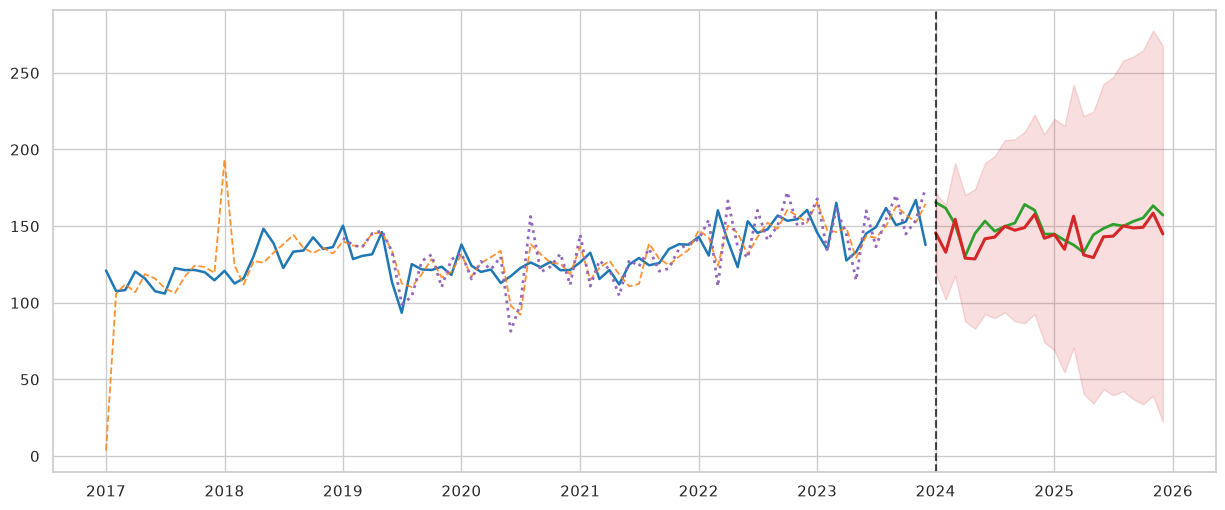

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX

# ==============================================================================
# 1. PARAMETER MODEL & PERSIAPAN DATA TARGET DAN EKSOGEN
# ==============================================================================
exog_cols = ['netWgt', 'yj_netwgt_yoy']

# Gunakan ordo terbaik hasil identifikasi / grid search
order = (1, 1, 0)
seasonal_order = (0, 1, 1, 12)

# Pastikan data sejajar dan bebas missing value
df_train_model = train_final[['ipi_tembakau'] + exog_cols].dropna()
df_test_model = test_final[['ipi_tembakau'] + exog_cols].dropna()

y_train = df_train_model['ipi_tembakau']
X_train = df_train_model[exog_cols]

y_test = df_test_model['ipi_tembakau']
X_test = df_test_model[exog_cols]

# Jendela minimal inisialisasi parameter (24 bulan)
min_train_len = 24  
oof_series = pd.Series(index=df_train_model.index, dtype=float)

# ==============================================================================
# 2. EXPANDING WINDOW ONE-STEP-AHEAD WALK-FORWARD (DATA TRAIN)
# ==============================================================================
# Gunakan .values agar tidak terhambat validasi frekuensi indeks Pandas
init_y = y_train.iloc[:min_train_len].values
init_X = X_train.iloc[:min_train_len].values

init_model = SARIMAX(
    endog=init_y,
    exog=init_X,
    order=order,
    seasonal_order=seasonal_order,
    enforce_stationarity=False,
    enforce_invertibility=False,
).fit(disp=False, maxiter=100)

current_res = init_model

# Ramalan 1 langkah pertama (t = 24 / bulan ke-25)
exog_first_step = X_train.iloc[min_train_len : min_train_len + 1].values
pred_first = current_res.forecast(steps=1, exog=exog_first_step)
oof_series.iloc[min_train_len] = pred_first[0]

# Gulirkan jendela secara expanding satu bulan ke depan hingga akhir data latih
for t in range(min_train_len + 1, len(df_train_model)):
  # Tambahkan data bulan t-1 ke state filter kalman dalam bentuk array
  y_last = y_train.iloc[t - 1 : t].values
  X_last = X_train.iloc[t - 1 : t].values
  current_res = current_res.extend(endog=y_last, exog=X_last)

  # Ambil nilai eksogen bulan t untuk meramal periode t
  exog_t = X_train.iloc[t : t + 1].values
  pred_step = current_res.forecast(steps=1, exog=exog_t)
  oof_series.iloc[t] = pred_step[0]
# ==============================================================================
# 3. FULL FIT PADA DATA TRAIN & FORECAST PADA TEST SET DENGAN EKSOGEN TEST
# ==============================================================================
full_model = SARIMAX(
    endog=y_train,
    exog=X_train,
    order=order,
    seasonal_order=seasonal_order,
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

# In-sample fitted values
fit_train = full_model.fittedvalues

# Forecast untuk data uji dengan menyertakan seluruh eksogen data uji
forecast_res = full_model.get_forecast(steps=len(df_test_model), exog=X_test)
pred_test = forecast_res.predicted_mean
pred_test.index = df_test_model.index
conf_int = forecast_res.conf_int()

# ==============================================================================
# 4. VISUALISASI LENGKAP
# ==============================================================================
plt.figure(figsize=(15, 6))

# Garis Data Aktual
plt.plot(df_train_model.index, y_train, label='Aktual Train', color='#1f77b4', linewidth=1.8)
plt.plot(df_test_model.index, y_test, label='Aktual Test', color='#2ca02c', linewidth=2.0)

# Garis Prediksi SARIMAX
plt.plot(df_train_model.index, fit_train, label='SARIMAX Fit in-Train', color='#ff7f0e', linestyle='--', linewidth=1.3, alpha=0.85)
plt.plot(oof_series.dropna().index, oof_series.dropna(), label='SARIMAX Walk-Forward OOF (1-Step)', color='#9467bd', linestyle=':', linewidth=2.0)
plt.plot(df_test_model.index, pred_test, label='SARIMAX Test Forecast', color='#d62728', linewidth=2.2)

# Interval Keyakinan 95% untuk Forecast Test
plt.fill_between(
    df_test_model.index,
    conf_int.iloc[:, 0],
    conf_int.iloc[:, 1],
    color='#d62728',
    alpha=0.15,
    label='95% Confidence Interval (Test)'
)

# Garis Pemisah Train dan Test
split_point = df_test_model.index[0]
plt.axvline(x=split_point, color='black', linestyle='--', alpha=0.7, label=f'Split Point ({split_point.strftime("%b %Y")})')

# Garis Awal Mul

=== Hasil Uji Ljung-Box Residu ===


,lb_stat,lb_pvalue
6,5.196529,0.518865
12,14.820350,0.251408
18,18.981583,0.392958
24,21.174321,0.628421


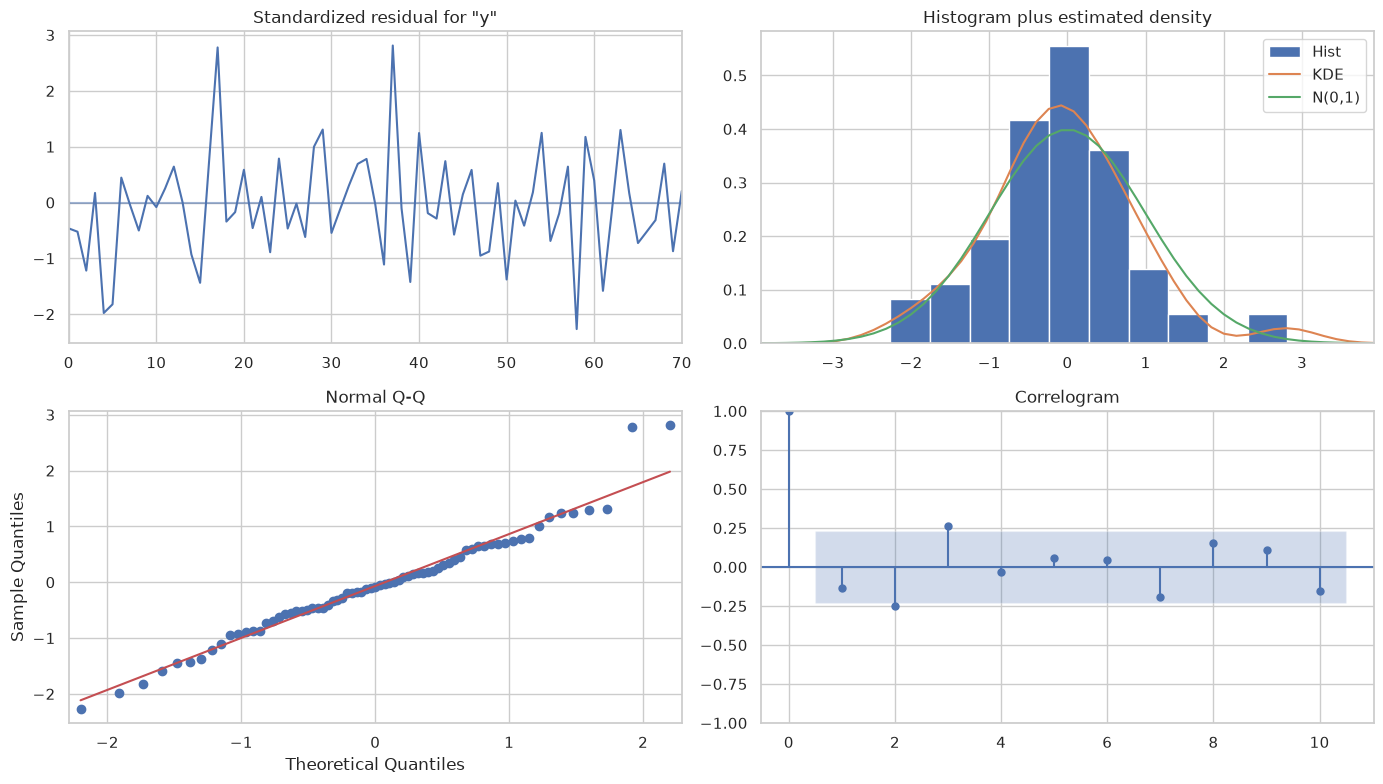

In [ ]:
import matplotlib.pyplot as plt
from statsmodels.stats.diagnostic import acorr_ljungbox

# Ambil residu model
residuals = res.resid

# 1. Uji Ljung-Box (p-value > 0.05 menandakan residu adalah white noise murni)
lb_test = acorr_ljungbox(residuals, lags=[6, 12, 18, 24], return_df=True)
print("=== Hasil Uji Ljung-Box Residu ===")
display(lb_test)

# 2. Plot 4 Diagnostik Residu
res.plot_diagnostics(figsize=(14, 8))
plt.tight_layout()
plt.show()